# Airbnb business insights — 02 · Predictive modelling
1. Prepare the inputs (features) and the target: the **log of the price** (prices are very skewed, see notebook 01)
2. **Put 20% of the listings aside as a test set.** It is not used until the very end.
3. On the other 80% (the training data), **compare two models with 5-fold cross-validation**:
   - **Linear regression**: simple and easy to explain
   - **Random forest**: more flexible, can capture more complex patterns
4. **Tune the random forest** with cross-validation (still on the training data only)
5. **Score the test set once** with the final models
6. Look at what drives price (the useful part for the client)
7. Use the model for a fair-price check on unseen listings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

from common import CORAL, INK2, LABELS, MUTED, TEAL, load, save, style

style()
pd.set_option("display.width", 200)
df = load()
df.shape

(51707, 22)

## 1 · Inputs (features) and target
- **City** is text, so it is turned into 0/1 columns (one per city; Amsterdam is the baseline).
- **Left out:** latitude/longitude, the raw attraction/restaurant indices, and the `room_type` text (the 0/1 columns `is_entire_home` and `is_shared_room` already cover it).

In [2]:
# Inputs: numbers and 0/1 columns
feature_cols = [
    "person_capacity", "bedrooms", "is_entire_home", "is_shared_room",
    "host_is_superhost", "multi", "biz", "cleanliness_rating",
    "guest_satisfaction_overall", "dist", "metro_dist",
    "attr_index_norm", "rest_index_norm", "weekday",
]

# City becomes 0/1 columns (Amsterdam is the baseline)
X = pd.get_dummies(df[feature_cols + ["city"]], columns=["city"], drop_first=True, dtype=int)

y_log = df["log_price"]     # what the models learn
y_raw = df["price"]         # real price, used for scoring

print("Inputs:", X.shape[1], "columns")
X.head()

Inputs: 23 columns


,person_capacity,bedrooms,is_entire_home,is_shared_room,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,dist,...,weekday,city_Athens,city_Barcelona,city_Berlin,city_Budapest,city_Lisbon,city_London,city_Paris,city_Rome,city_Vienna
0,2.0,1,0,0,0,0,0,6.0,69.0,5.734117,...,0,0,0,0,0,0,1,0,0,0
1,2.0,1,0,0,0,1,0,10.0,96.0,4.788905,...,0,0,0,0,0,0,1,0,0,0
2,3.0,1,0,0,0,1,0,10.0,95.0,4.596677,...,0,0,0,0,0,0,1,0,0,0
3,2.0,1,0,0,0,1,0,9.0,87.0,2.054769,...,0,0,0,0,0,0,1,0,0,0
4,3.0,0,1,0,0,0,1,7.0,65.0,4.491277,...,0,0,0,0,0,0,1,0,0,0


## 2 · Training set and test set

In [3]:
# 80% train, 20% test
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train_log = y_log.loc[train_idx]
y_train_raw = y_raw.loc[train_idx]
y_test_raw = y_raw.loc[test_idx]

print("Training listings:", len(X_train))
print("Test listings:    ", len(X_test), "(put aside)")

Training listings: 41365
Test listings:     10342 (put aside)


## 3 · How we measure the models

| Measure | What it means | Better is |
|---|---|---|
| **MAE** | Average miss in dollars (how far off a typical prediction is) | lower |
| **Median % error** | The typical miss as a percentage of the real price | lower |
| **R²** | Share of the price differences the model explains (1 = perfect, 0 = no better than always guessing the average price) | higher |

In [4]:
def score(name, actual, predicted):
    return {
        "model": name,
        "MAE ($)": round(mean_absolute_error(actual, predicted), 1),
        "median % error": round((abs(predicted - actual) / actual).median() * 100, 1),
        "R²": round(r2_score(actual, predicted), 3),
    }

## 4 · Comparing the models with cross-validation

In [5]:
# 5 parts of the training data
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_numbers = {}     # mean and spread of the median % error, for the progress chart

def cv_scores(name, model):
    # Train on 4 parts, score on the 5th, repeat 5 times
    fold_scores = []
    for fit_rows, check_rows in kfold.split(X_train):
        m = clone(model).fit(X_train.iloc[fit_rows], y_train_log.iloc[fit_rows])
        predicted = pd.Series(np.exp(m.predict(X_train.iloc[check_rows])), index=X_train.index[check_rows])
        fold_scores.append(score(name, y_train_raw.iloc[check_rows], predicted))
    s = pd.DataFrame(fold_scores)
    cv_numbers[name] = (s["median % error"].mean(), s["median % error"].std())
    return {
        "model": name,
        "MAE ($)": f"{s['MAE ($)'].mean():.1f} ± {s['MAE ($)'].std():.1f}",
        "median % error": f"{s['median % error'].mean():.1f} ± {s['median % error'].std():.1f}",
        "R²": f"{s['R²'].mean():.3f} ± {s['R²'].std():.3f}",
    }

cv_results = [
    cv_scores("Linear regression", LinearRegression()),
    cv_scores("Random forest (original settings)",
              RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)),
]
pd.DataFrame(cv_results).set_index("model")

,MAE ($),median % error,R²
model,,,
Linear regression,79.4 ± 5.5,20.6 ± 0.4,0.302 ± 0.109
Random forest (original settings),66.3 ± 4.6,15.6 ± 0.1,0.375 ± 0.136


## 5 · Tuning the random forest (cross-validation)

In [6]:
# 5 x 2 x 2 = 20 combinations
param_grid = {
    "min_samples_leaf": [1, 2, 3, 5, 10],
    "max_depth": [15, None],
    "max_features": [0.5, 1.0],
}

# Error on the log price (lower is better); training data only
search = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42),
    param_grid, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1,
)
search.fit(X_train, y_train_log)

print("Best settings:", search.best_params_)

# All 20 combinations, best first
cv_table = pd.DataFrame(search.cv_results_)[["param_min_samples_leaf", "param_max_depth", "param_max_features", "mean_test_score"]]
cv_table["cv_error (log units)"] = (-cv_table["mean_test_score"]).round(4)
cv_table.drop(columns="mean_test_score").sort_values("cv_error (log units)").reset_index(drop=True)

Best settings: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}


,param_min_samples_leaf,param_max_depth,param_max_features,cv_error (log units)
0,1,None,0.5,0.1922
1,1,None,1.0,0.1931
2,2,None,1.0,0.1982
3,2,None,0.5,0.1997
4,3,None,1.0,0.2036
5,3,None,0.5,0.2055
6,1,15,1.0,0.2108
7,1,15,0.5,0.2113
8,5,None,1.0,0.2118
9,2,15,1.0,0.2123


In [7]:
# Best settings, 200 trees, same 5-fold check as before
rf_tuned = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **search.best_params_)

cv_results.append(cv_scores("Random forest (tuned)", rf_tuned))
pd.DataFrame(cv_results).set_index("model")

,MAE ($),median % error,R²
model,,,
Linear regression,79.4 ± 5.5,20.6 ± 0.4,0.302 ± 0.109
Random forest (original settings),66.3 ± 4.6,15.6 ± 0.1,0.375 ± 0.136
Random forest (tuned),59.6 ± 4.5,13.4 ± 0.1,0.434 ± 0.157


### The progress so far
The typical error (median % error, cross-validated) at each step. The thin line on each bar shows the spread across the 5 folds. Lower is better.

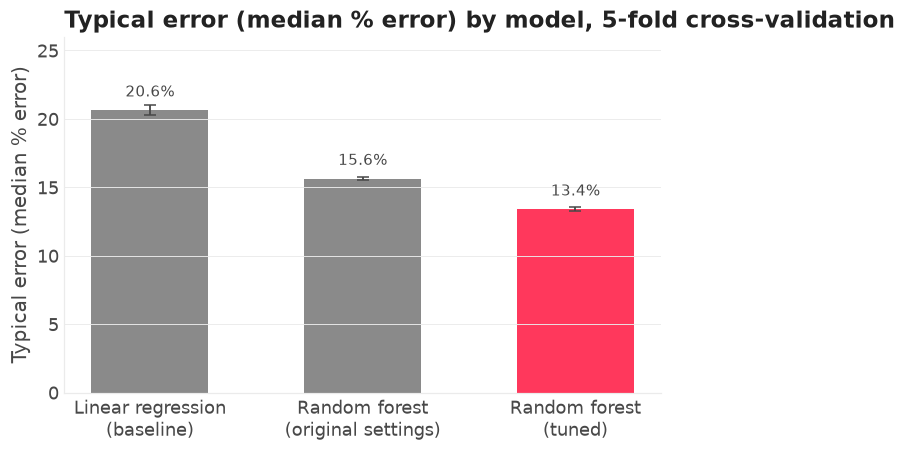

In [8]:
names = list(cv_numbers)
means = [cv_numbers[n][0] for n in names]
spreads = [cv_numbers[n][1] for n in names]
labels = ["Linear regression\n(baseline)", "Random forest\n(original settings)", "Random forest\n(tuned)"]

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(labels, means, yerr=spreads, color=[MUTED, MUTED, CORAL], width=0.55,
              error_kw=dict(ecolor=INK2, lw=1.2, capsize=4))
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width() / 2, m + 1.0, f"{m:.1f}%", ha="center", fontsize=10, color=INK2)
ax.set_ylabel("Typical error (median % error)")
ax.set_ylim(0, 26)
ax.set_title("Typical error (median % error) by model, 5-fold cross-validation")
ax.grid(axis="x", visible=False)
save(fig, "11_model_progress");

**What the chart shows:** the typical error falls at each step: 20.6% for the linear regression, 15.6% for the random forest with its original settings, and 13.4% after tuning. The thin lines on the bars (the spread across the 5 folds) are very small, so the result is stable.

## 6 · Final check on the test set

In [9]:
# Both models learn from all training listings
final_models = {
    "Linear regression": LinearRegression(),
    "Random forest (tuned)": rf_tuned,
}

# Predict the test listings (log price back to dollars with exp)
test_preds = {}
for name, model in final_models.items():
    model.fit(X_train, y_train_log)
    test_preds[name] = pd.Series(np.exp(model.predict(X_test)), index=X_test.index)

pd.DataFrame([score(name, y_test_raw, p) for name, p in test_preds.items()]).set_index("model")

,MAE ($),median % error,R²
model,,,
Linear regression,80.8,20.6,0.290
Random forest (tuned),55.2,12.2,0.604


### 6b · Predicted vs. real price on the test listings: baseline vs. final model

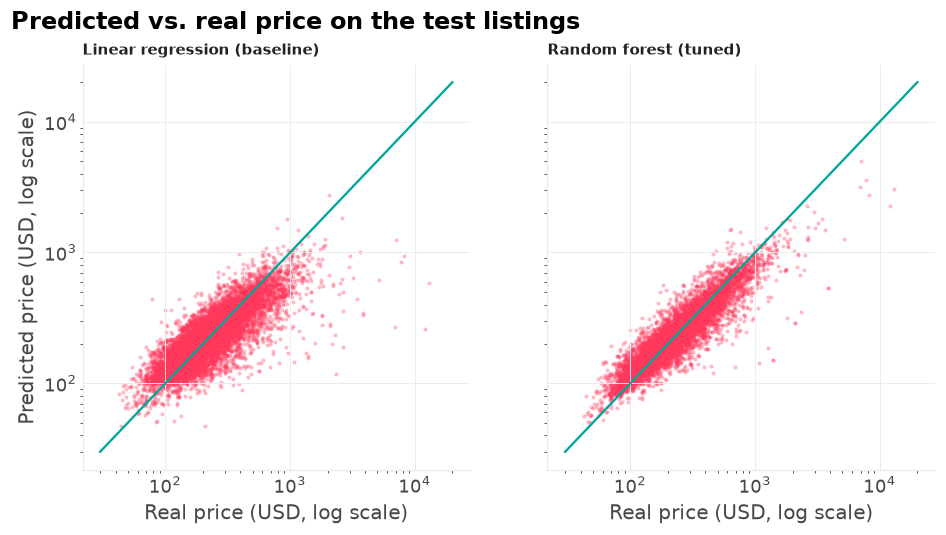

In [10]:
# One dot per test listing; the teal line is a perfect prediction
preds = {"Linear regression (baseline)": test_preds["Linear regression"],
         "Random forest (tuned)": test_preds["Random forest (tuned)"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test_raw, p, s=3, alpha=0.25, color=CORAL)
    ax.plot([30, 20000], [30, 20000], color=TEAL, lw=1.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Real price (USD, log scale)")
axes[0].set_ylabel("Predicted price (USD, log scale)")
fig.suptitle("Predicted vs. real price on the test listings", x=0.06, ha="left", fontweight="bold")
save(fig, "08_predicted_vs_actual");

### 6c · How close are the predictions?
For a listing with a real price of $200, "within 10%" means a predicted price between $180 and $220. The chart shows, for the final model, the share of the test listings for which the prediction is within 10%, 20%, 30% and 50% of the real price.

Half of the predictions are within 12.2% of the real price (the median error).
The 10% worst predictions are off by 38% or more.


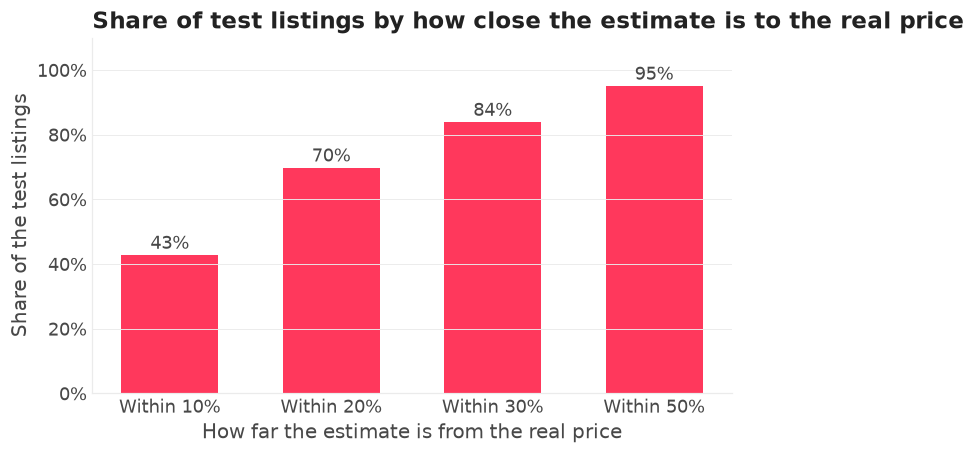

In [11]:
# Error of each prediction as a share of the real price
error_share = abs(test_preds["Random forest (tuned)"] - y_test_raw) / y_test_raw

print(f"Half of the predictions are within {error_share.median():.1%} of the real price (the median error).")
print(f"The 10% worst predictions are off by {error_share.quantile(0.9):.0%} or more.")

# Share of test listings within each band
bands = [0.10, 0.20, 0.30, 0.50]
share_within = [(error_share <= b).mean() for b in bands]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar([f"Within {b:.0%}" for b in bands], share_within, color=CORAL, width=0.6)
for bar, v in zip(bars, share_within):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=12, color=INK2)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Share of the test listings")
ax.set_xlabel("How far the estimate is from the real price")
ax.set_title("Share of test listings by how close the estimate is to the real price")
ax.grid(axis="x", visible=False)
save(fig, "13_accuracy_bands");

## 7 · What drives price? (the useful part for the client)

### 7a · Which inputs matter most?

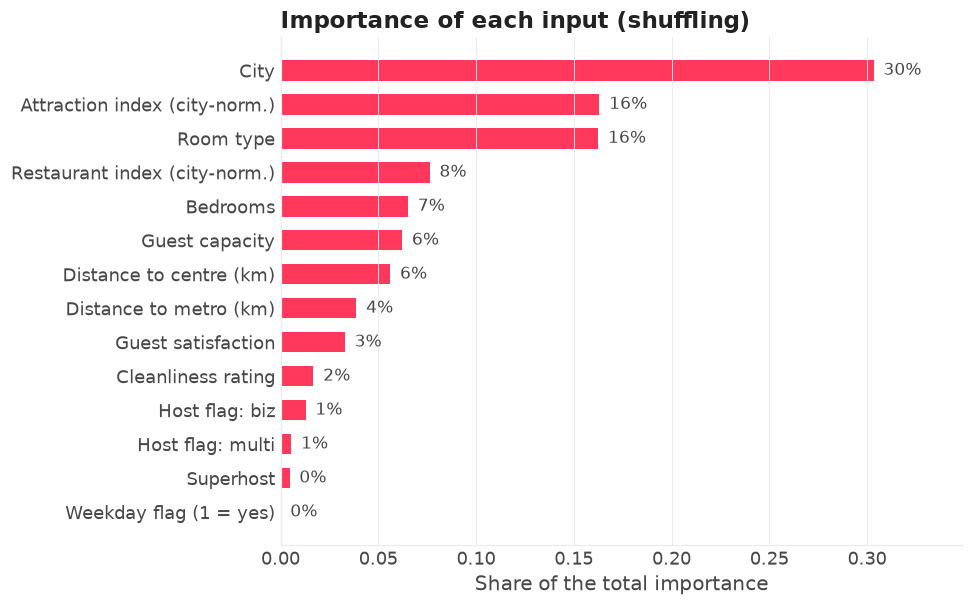

In [12]:
# Hold back part of the training data to measure importance (the test set stays untouched)
fit_idx, val_idx = train_test_split(X_train.index, test_size=0.25, random_state=1)
rf_check = clone(rf_tuned).fit(X_train.loc[fit_idx], y_train_log.loc[fit_idx])
X_val, y_val = X_train.loc[val_idx], y_train_log.loc[val_idx]
base_error = np.mean(abs(rf_check.predict(X_val) - y_val))

# City and room type are shuffled as a group; every other input on its own
city_cols = [c for c in X.columns if c.startswith("city_")]
room_cols = ["is_entire_home", "is_shared_room"]
inputs = {"City": city_cols, "Room type": room_cols}
for col in X.columns:
    if col not in city_cols + room_cols:
        inputs[LABELS[col]] = [col]

def shuffle_loss(cols, repeats=5):
    # How much worse the predictions get when these columns are shuffled (average of 5 shuffles)
    rng = np.random.default_rng(0)
    losses = []
    for _ in range(repeats):
        X_shuffled = X_val.copy()
        X_shuffled[cols] = X_val[cols].values[rng.permutation(len(X_val))]
        losses.append(np.mean(abs(rf_check.predict(X_shuffled) - y_val)) - base_error)
    return np.mean(losses)

loss = pd.Series({name: shuffle_loss(cols) for name, cols in inputs.items()})
loss = loss.clip(lower=0)               # tiny negative values are noise
importance = loss / loss.sum()          # share of the total

order = importance.sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(order, importance[order], color=CORAL, height=0.6)
for i, name in enumerate(order):
    ax.text(importance[name] + 0.005, i, f"{importance[name]:.0%}", va="center", fontsize=11, color=INK2)
ax.set_xlim(0, importance.max() * 1.15)
ax.set_xlabel("Share of the total importance")
ax.set_title("Importance of each input (shuffling)")
ax.grid(axis="y", visible=False)
save(fig, "10_rf_importance");

### 7b · Putting the inputs into themes

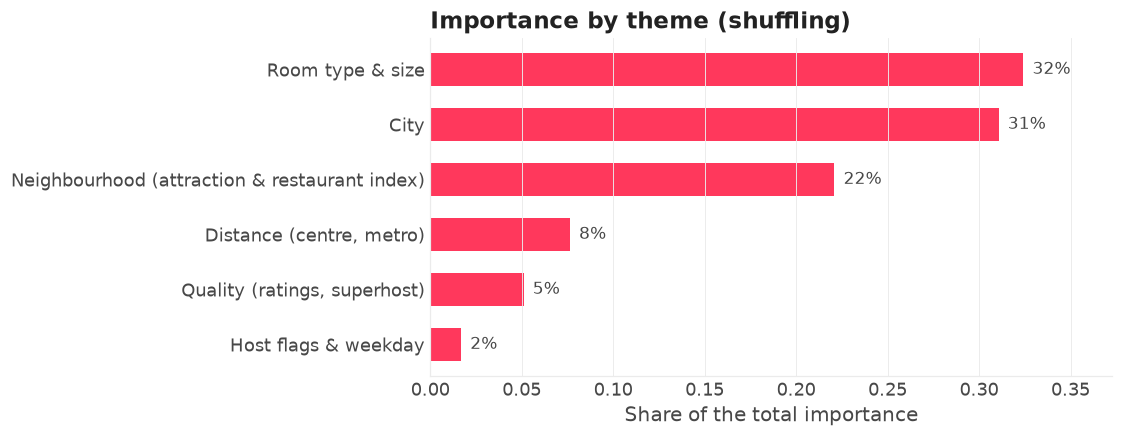

In [13]:
themes = {
    "City": city_cols,
    "Room type & size": room_cols + ["bedrooms", "person_capacity"],
    "Neighbourhood (attraction & restaurant index)": ["attr_index_norm", "rest_index_norm"],
    "Distance (centre, metro)": ["dist", "metro_dist"],
    "Quality (ratings, superhost)": ["cleanliness_rating", "guest_satisfaction_overall", "host_is_superhost"],
    "Host flags & weekday": ["multi", "biz", "weekday"],
}

# Shuffle each theme as a group, as above
theme_loss = pd.Series({name: shuffle_loss(cols) for name, cols in themes.items()})
theme_importance = (theme_loss / theme_loss.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(theme_importance.index, theme_importance.values, color=CORAL, height=0.6)
for i, v in enumerate(theme_importance.values):
    ax.text(v + 0.005, i, f"{v:.0%}", va="center", fontsize=11, color=INK2)
ax.set_xlim(0, theme_importance.max() * 1.15)
ax.set_xlabel("Share of the total importance")
ax.set_title("Importance by theme (shuffling)")
ax.grid(axis="y", visible=False)
save(fig, "12_feature_groups");

### 7c · A closer look at the attraction and restaurant index

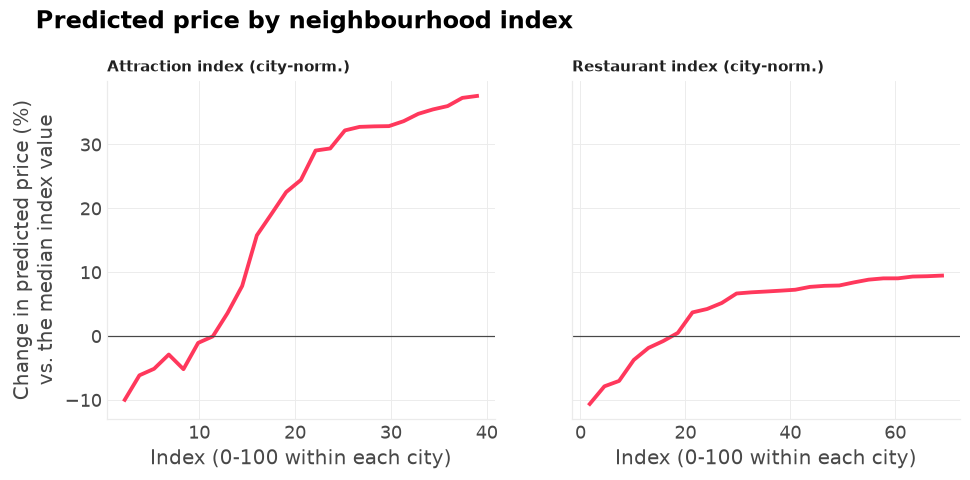

In [14]:
sample = X_train.sample(5000, random_state=42)      # a sample keeps it fast

def price_curve(column, n_points=25):
    # Give every listing in the sample the same value of this input and average the predicted price
    values = np.linspace(X_train[column].quantile(0.02), X_train[column].quantile(0.98), n_points)
    avg_log_price = []
    for v in values:
        s = sample.copy()
        s[column] = v
        avg_log_price.append(rf_tuned.predict(s).mean())
    avg_log_price = np.array(avg_log_price)
    # % change compared with the median value of the input
    middle = np.interp(X_train[column].median(), values, avg_log_price)
    return values, (np.exp(avg_log_price - middle) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col in zip(axes, ["attr_index_norm", "rest_index_norm"]):
    x, change = price_curve(col)
    ax.plot(x, change, color=CORAL, lw=2.5)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xlabel("Index (0-100 within each city)")
    ax.set_title(LABELS[col], fontsize=10)
axes[0].set_ylabel("Change in predicted price (%)\nvs. the median index value")
fig.suptitle("Predicted price by neighbourhood index", x=0.06, y=1.04, ha="left", fontweight="bold")
save(fig, "14_index_effect");

## 8 · Using the model: a fair-price check on unseen listings
> **price gap = real price ÷ predicted price − 1**


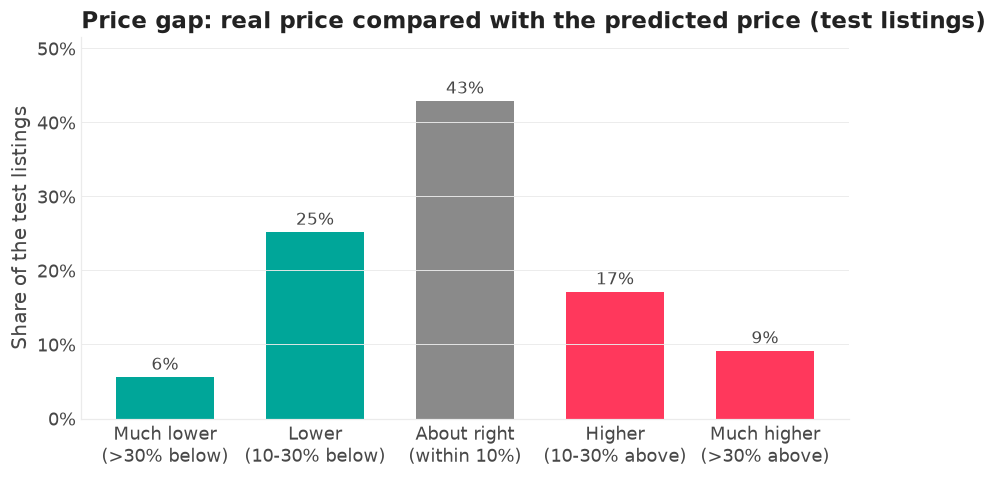

In [15]:
# One row per test listing: real price, predicted price and the gap
check = df.loc[X_test.index, ["city", "room_type", "person_capacity", "guest_satisfaction_overall"]].copy()
check["real_price"] = y_test_raw
check["predicted_price"] = test_preds["Random forest (tuned)"]
check["gap"] = check["real_price"] / check["predicted_price"] - 1      # 0.50 = 50% above the prediction

# Five groups, from much lower to much higher than the prediction
group_names = ["Much lower\n(>30% below)", "Lower\n(10-30% below)", "About right\n(within 10%)",
               "Higher\n(10-30% above)", "Much higher\n(>30% above)"]
check["group"] = pd.cut(check["gap"], bins=[-np.inf, -0.30, -0.10, 0.10, 0.30, np.inf], labels=group_names)
share = check["group"].value_counts(normalize=True).reindex(group_names)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(group_names, share.values, color=[TEAL, TEAL, MUTED, CORAL, CORAL], width=0.65)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}", ha="center", fontsize=11, color=INK2)
ax.set_ylabel("Share of the test listings")
ax.set_ylim(0, share.max() * 1.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Price gap: real price compared with the predicted price (test listings)")
ax.grid(axis="x", visible=False)
save(fig, "15_price_gap");

In [16]:
# Gap combined with guest satisfaction
hidden_gems = (check["gap"] < -0.20) & (check["guest_satisfaction_overall"] >= 95)     # cheap and loved
to_review = (check["gap"] > 0.30) & (check["guest_satisfaction_overall"] < 90)         # expensive and less loved
pd.DataFrame({
    "listings": [hidden_gems.sum(), to_review.sum()],
    "share of the test listings": [f"{hidden_gems.mean():.1%}", f"{to_review.mean():.1%}"],
}, index=["Priced 20%+ below the prediction and satisfaction 95+ (good value)",
          "Priced 30%+ above the prediction and satisfaction below 90 (worth a look)"])

,listings,share of the test listings
Priced 20%+ below the prediction and satisfaction 95+ (good value),810,7.8%
Priced 30%+ above the prediction and satisfaction below 90 (worth a look),211,2.0%
